In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# --- Chart theme ---------------------------------------------------------
# The built-in "ggplot" theme supplies the whole look: grey panel, white grid,
# and its own colour cycle. The only thing we take from it by hand are the first
# two cycle colours, so the risk/safe rule stays the same on every chart.
plt.style.use("ggplot")

RISK, SAFE = plt.rcParams["axes.prop_cycle"].by_key()["color"][:2]   # red, blue

print("Libraries loaded. pandas", pd.__version__, "| numpy", np.__version__)
print("ggplot theme applied - risk =", RISK, "| safe =", SAFE)

Libraries loaded. pandas 3.0.2 | numpy 2.4.4
ggplot theme applied - risk = #E24A33 | safe = #348ABD


In [2]:
url = "https://raw.githubusercontent.com/YBIFoundation/Dataset/main/TelecomCustomerChurn.csv"
df = pd.read_csv(url)

print("Rows:", df.shape[0], " Columns:", df.shape[1])

Rows: 7043  Columns: 21


In [3]:
df.head()

,customerID,Gender,SeniorCitizen,Partner,Dependents,Tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Monthly,Yes,Manual,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Manual,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Monthly,Yes,Manual,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Monthly,Yes,Manual,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   Gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   Tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing values after conversion:", df["TotalCharges"].isnull().sum())

Missing values after conversion: 11


In [6]:
missing = df[df["TotalCharges"].isnull()]
print("Tenure values among rows with a missing TotalCharges:", missing["Tenure"].unique())
missing[["Tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]

Tenure values among rows with a missing TotalCharges: [0]


,Tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,0,52.55,NaN,Two year,No
753,0,20.25,NaN,Two year,No
936,0,80.85,NaN,Two year,No
1082,0,25.75,NaN,Two year,No
1340,0,56.05,NaN,Two year,No
3331,0,19.85,NaN,Two year,No
3826,0,25.35,NaN,Two year,No
4380,0,20.00,NaN,Two year,No
5218,0,19.70,NaN,One year,No
6670,0,73.35,NaN,Two year,No


In [7]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Remaining nulls across the whole dataframe:", df.isnull().sum().sum())

Remaining nulls across the whole dataframe: 0


In [8]:
print("Fully duplicated rows :", df.duplicated().sum())
print("Duplicated customerIDs:", df["customerID"].duplicated().sum())

# customerID is unique for every row, so it carries no signal - drop it.
df = df.drop(columns=["customerID"])
print("Shape after dropping customerID:", df.shape)

Fully duplicated rows : 0
Duplicated customerIDs: 0
Shape after dropping customerID: (7043, 20)


In [11]:
#for col in df.select_dtypes(include="object").columns:
    print(f"{col:<18} {df[col].nunique()} levels -> {sorted(df[col].unique())}"

IndentationError: unexpected indent (1482749260.py, line 2)

Churn
No     5174
Yes    1869

Overall churn rate: 26.54%


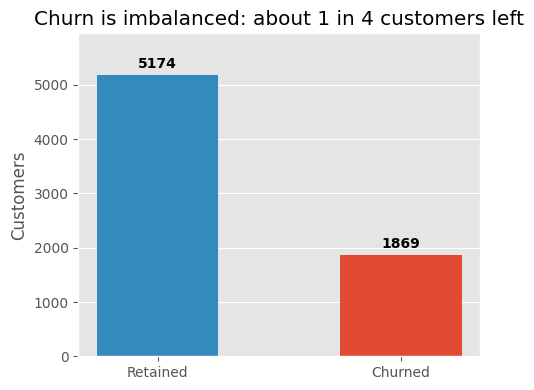

In [10]:
churn_counts = df["Churn"].value_counts()
BASELINE = (df["Churn"] == "Yes").mean() * 100      # the reference line used everywhere

print(churn_counts.to_string())
print(f"\nOverall churn rate: {BASELINE:.2f}%")

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["Retained", "Churned"],
              [churn_counts["No"], churn_counts["Yes"]],
              width=0.5, color=[SAFE, RISK])
ax.bar_label(bars, fmt="%d", padding=3, fontweight="bold")
ax.set_ylabel("Customers")
ax.set_title("Churn is imbalanced: about 1 in 4 customers left")
ax.set_ylim(0, churn_counts.max() * 1.15)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [12]:
def churn_by_category(column, data=None, ax=None, title=None, order=None, labels=None):
    # Plot churn rate (%) per level of `column`, annotated with the group size n.
    data = df if data is None else data
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4))

    rate = data.groupby(column)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
    size = data[column].value_counts()
    if order is not None:
        rate, size = rate.reindex(order), size.reindex(order)
    size = size.reindex(rate.index)

    # Group size goes in the tick label, where it can never collide with a short bar.
    names = [labels.get(i, str(i)) for i in rate.index] if labels else [str(i) for i in rate.index]
    names = [f"{name}\n(n={n:,})" for name, n in zip(names, size.values)]

    colors = [RISK if v >= BASELINE else SAFE for v in rate.values]
    bars = ax.bar(names, rate.values, width=0.55, color=colors)
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontweight="bold", fontsize=9)

    ax.axhline(BASELINE, color="#555555", linestyle="--", linewidth=1.2)
    ax.set_ylim(0, max(rate.max() * 1.28, BASELINE * 1.35))
    ax.set_ylabel("Churn rate (%)")
    ax.set_title(title or column)
    ax.grid(axis="x", visible=False)
    return ax

print(f"Helper ready. Baseline churn rate = {BASELINE:.2f}% (the dashed line on every chart)")

Helper ready. Baseline churn rate = 26.54% (the dashed line on every chart)


In [13]:
df[["Tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2)

,Tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


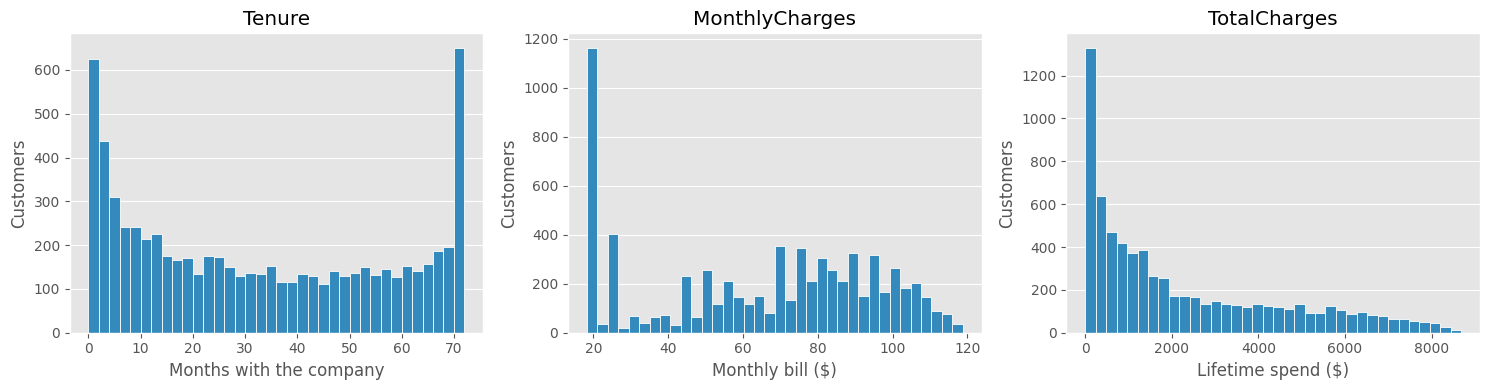

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

specs = [("Tenure",         "Months with the company", 36),
         ("MonthlyCharges", "Monthly bill ($)",        36),
         ("TotalCharges",   "Lifetime spend ($)",      36)]

for ax, (col, xlabel, bins) in zip(axes, specs):
    ax.hist(df[col], bins=bins, color=SAFE, edgecolor="white", linewidth=0.6)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Customers")
    ax.set_title(col)
    ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

In [15]:
#df["Gender"].value_counts()

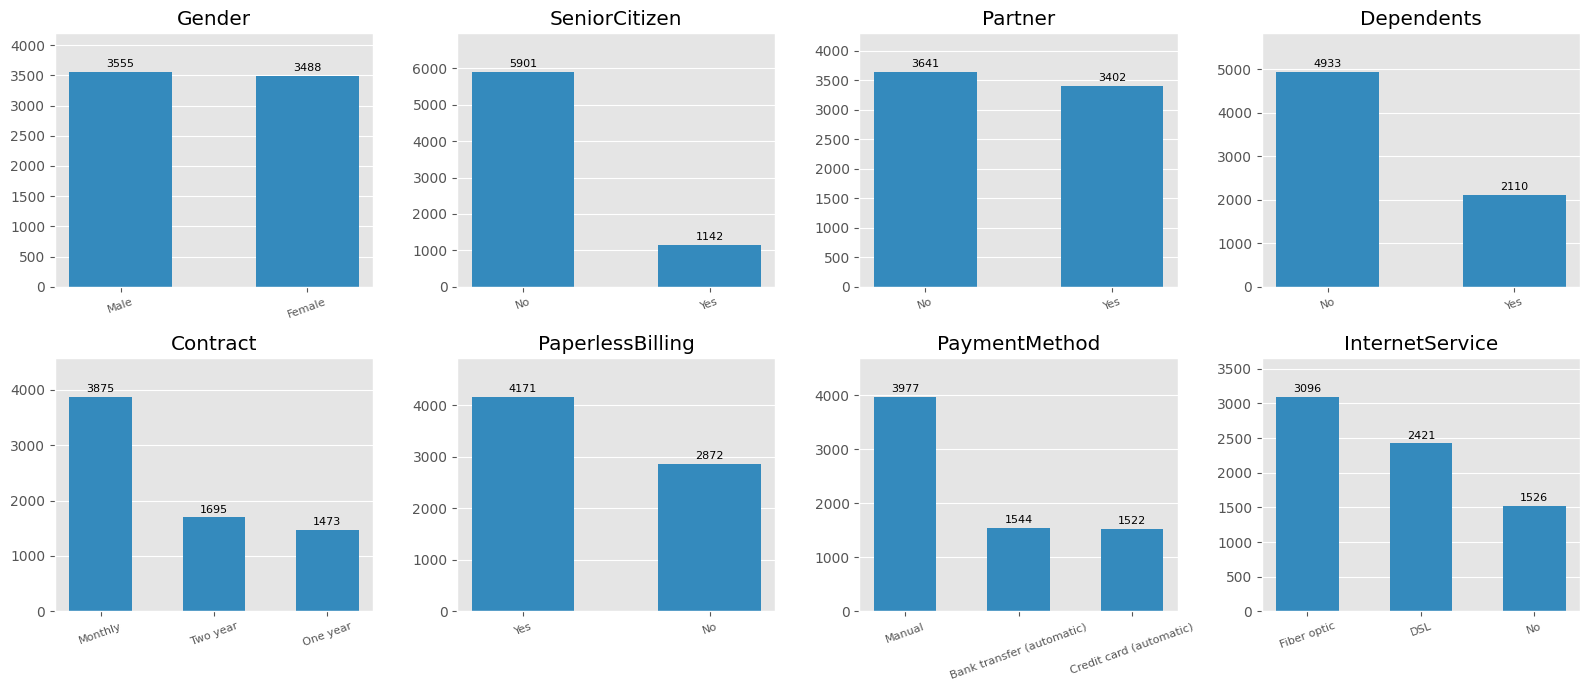

In [16]:
demo_cols = ["Gender", "SeniorCitizen", "Partner", "Dependents",
             "Contract", "PaperlessBilling", "PaymentMethod", "InternetService"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, demo_cols):
    counts = df[col].value_counts()
    names = ["No", "Yes"] if col == "SeniorCitizen" else [str(i) for i in counts.index]
    bars = ax.bar(names, counts.values, width=0.55, color=SAFE)
    ax.bar_label(bars, fmt="%d", padding=2, fontsize=8)
    ax.set_title(col)
    ax.set_ylim(0, counts.max() * 1.18)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelrotation=20, labelsize=8)

plt.tight_layout()
plt.show()

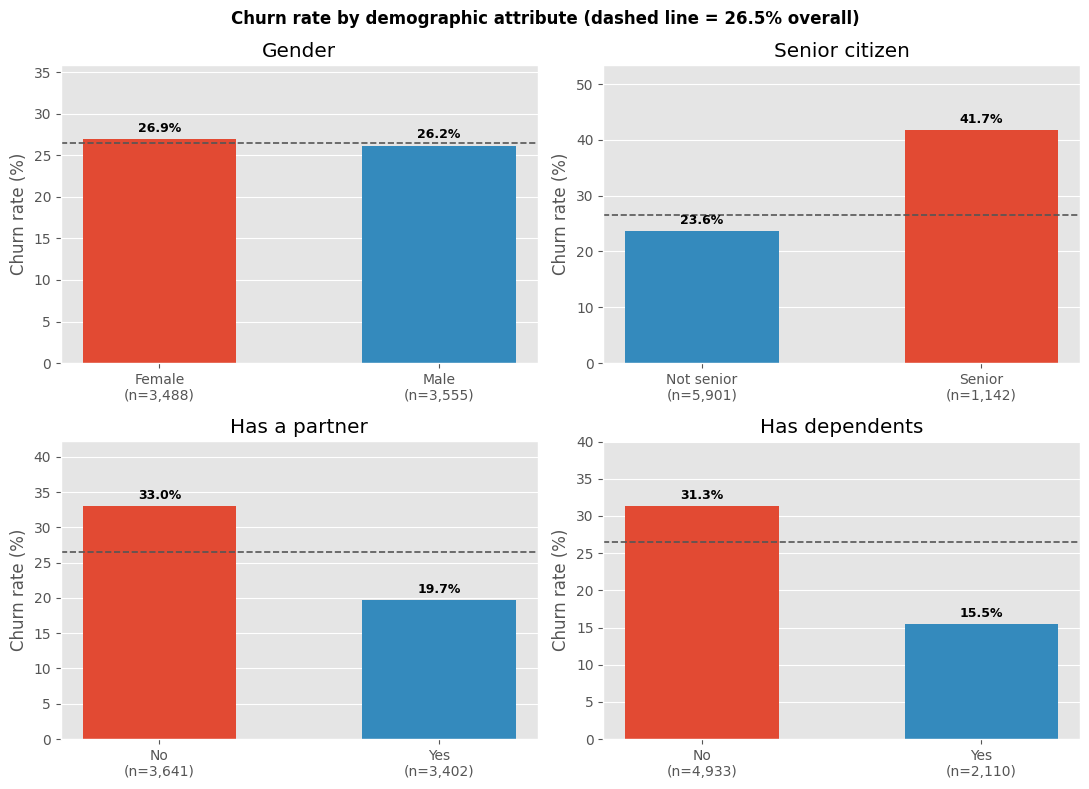

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

churn_by_category("Gender", ax=axes[0, 0], title="Gender")
churn_by_category("SeniorCitizen", ax=axes[0, 1], title="Senior citizen", order=[0, 1], labels={0: "Not senior", 1: "Senior"})
churn_by_category("Partner", ax=axes[1, 0], title="Has a partner")
churn_by_category("Dependents", ax=axes[1, 1], title="Has dependents")

fig.suptitle("Churn rate by demographic attribute (dashed line = 26.5% overall)",fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


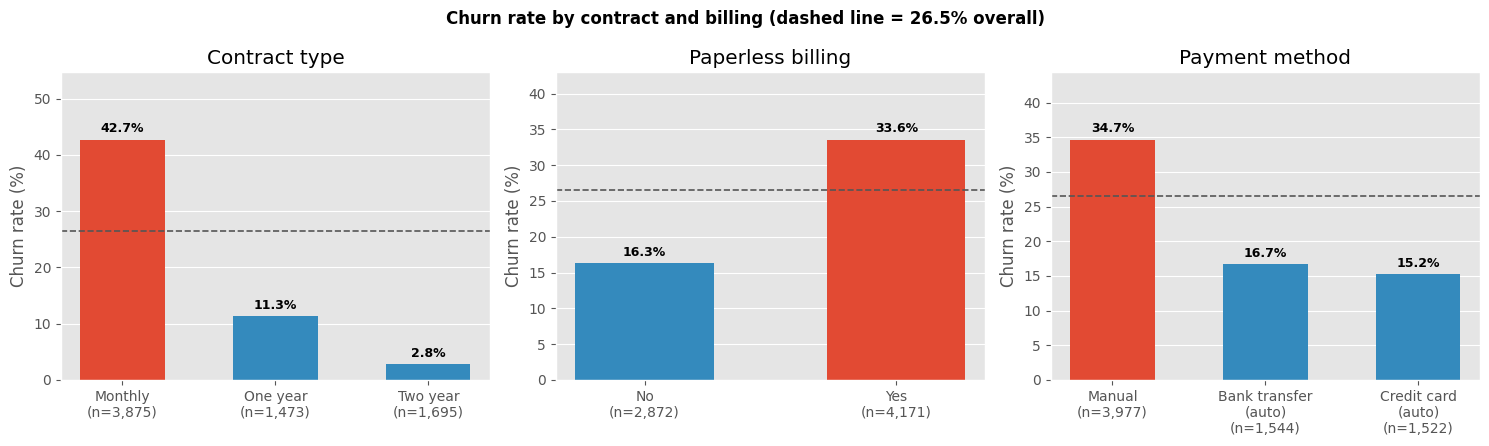

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

churn_by_category("Contract", ax=axes[0], title="Contract type",
                  order=["Monthly", "One year", "Two year"])
churn_by_category("PaperlessBilling", ax=axes[1], title="Paperless billing")
churn_by_category("PaymentMethod", ax=axes[2], title="Payment method",
                  order=["Manual", "Bank transfer (automatic)", "Credit card (automatic)"],
                  labels={"Bank transfer (automatic)": "Bank transfer\n(auto)",
                          "Credit card (automatic)": "Credit card\n(auto)"})

fig.suptitle("Churn rate by contract and billing (dashed line = 26.5% overall)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

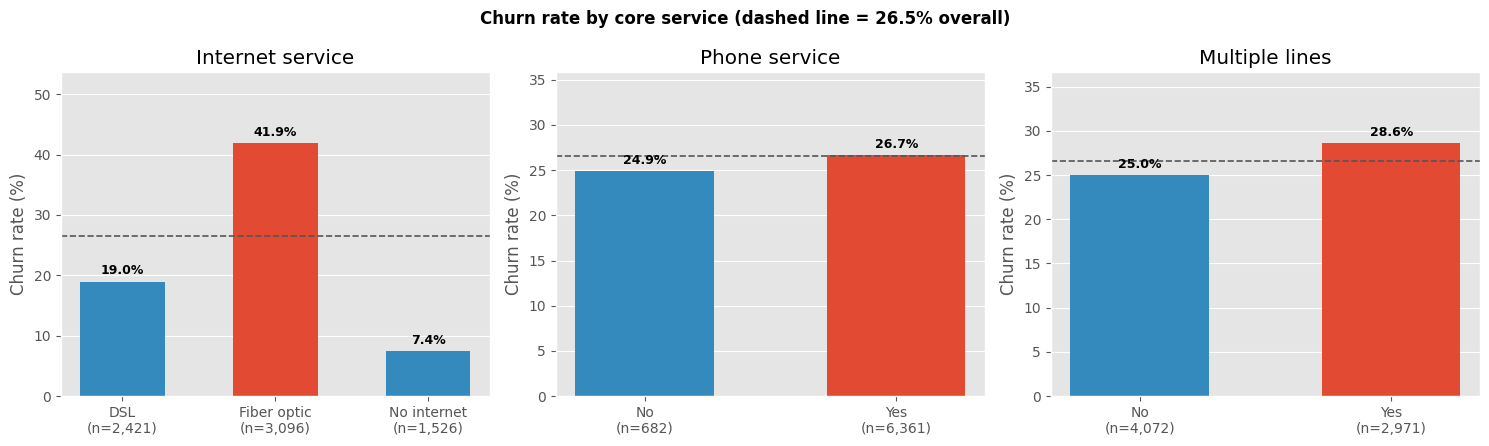

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

churn_by_category("InternetService", ax=axes[0], title="Internet service",
                  order=["DSL", "Fiber optic", "No"],
                  labels={"No": "No internet"})
churn_by_category("PhoneService",  ax=axes[1], title="Phone service")
churn_by_category("MultipleLines", ax=axes[2], title="Multiple lines")

fig.suptitle("Churn rate by core service (dashed line = 26.5% overall)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

In [20]:
print(df.groupby("InternetService")[["MonthlyCharges", "Tenure"]].mean().round(2).to_string())
print()
print("Fiber share of all churned customers: "
      f'{(df[df.Churn == "Yes"].InternetService.eq("Fiber optic").mean() * 100):.1f}%')

                 MonthlyCharges  Tenure
InternetService                        
DSL                       58.10   32.82
Fiber optic               91.50   32.92
No                        21.08   30.55

Fiber share of all churned customers: 69.4%


In [21]:
# internet = df[df["InternetService"] != "No"]      # internet subscribers only
# print(f"All customers          : n = {len(df):,}")
# print(f"Internet subscribers   : n = {len(internet):,}")
# print(f"Excluded (no internet) : n = {len(df) - len(internet):,}\n")

# addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
#           "TechSupport", "StreamingTV", "StreamingMovies"]

# comparison = pd.DataFrame({
#     "'No' churn %, all customers":   [df[df[c] == "No"]["Churn"].eq("Yes").mean() * 100 for c in addons],
#     "'No' churn %, internet only":   [internet[internet[c] == "No"]["Churn"].eq("Yes").mean() * 100 for c in addons],
# }, index=addons).round(1)
# comparison["distortion"] = (comparison.iloc[:, 1] - comparison.iloc[:, 0]).round(1)
# comparison

NameError: name 'addons' is not defined

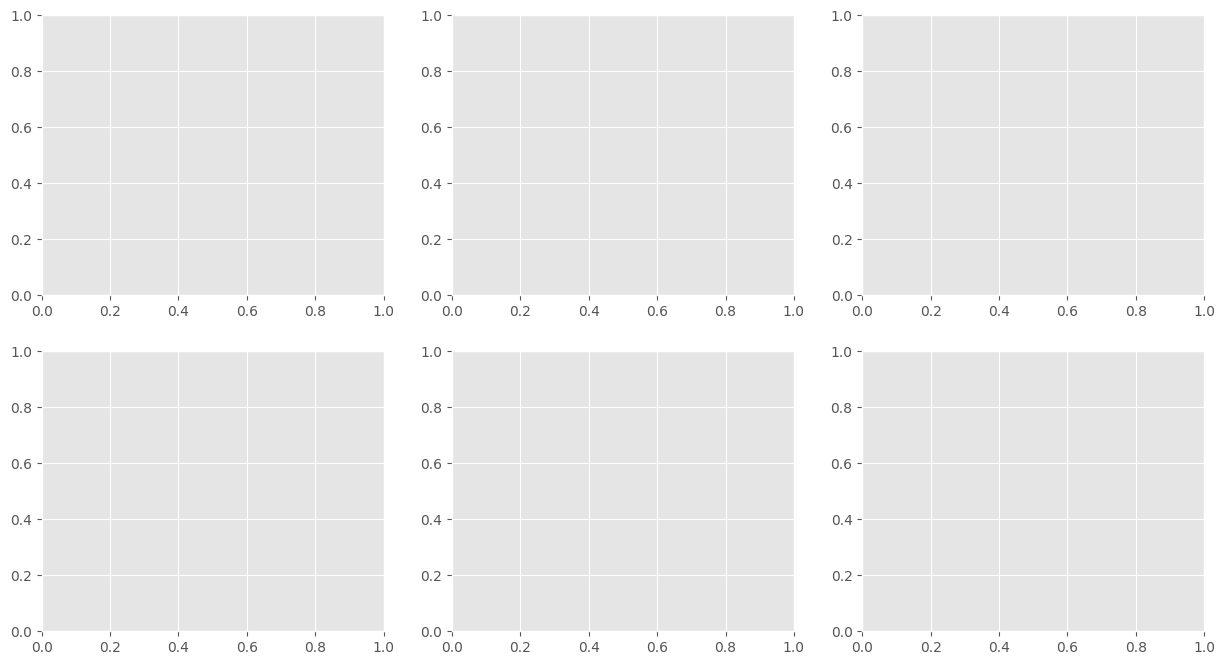

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, addons):
    churn_by_category(col, data=internet, ax=ax, title=col)

fig.suptitle("Churn rate by add-on service - internet subscribers only (n = 5,517)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

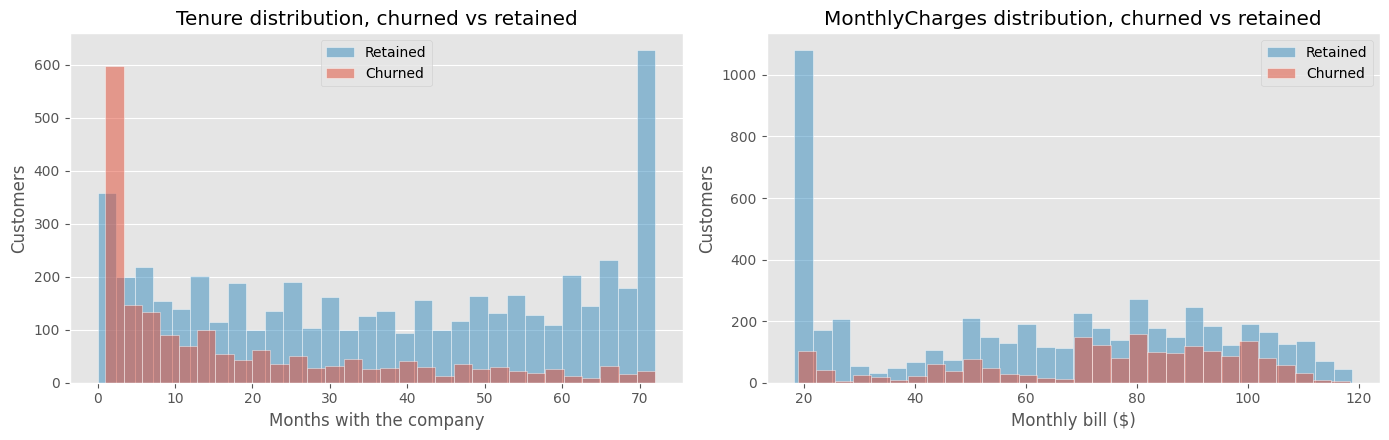

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for ax, col, xlabel in [(axes[0], "Tenure", "Months with the company"),
                        (axes[1], "MonthlyCharges", "Monthly bill ($)")]:
    ax.hist(df[df["Churn"] == "No"][col],  bins=30, alpha=0.5,
            color=SAFE, label="Retained", edgecolor="white", linewidth=0.6)
    ax.hist(df[df["Churn"] == "Yes"][col], bins=30, alpha=0.5,
            color=RISK, label="Churned",  edgecolor="white", linewidth=0.6)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Customers")
    ax.set_title(f"{col} distribution, churned vs retained")
    ax.legend()
    ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

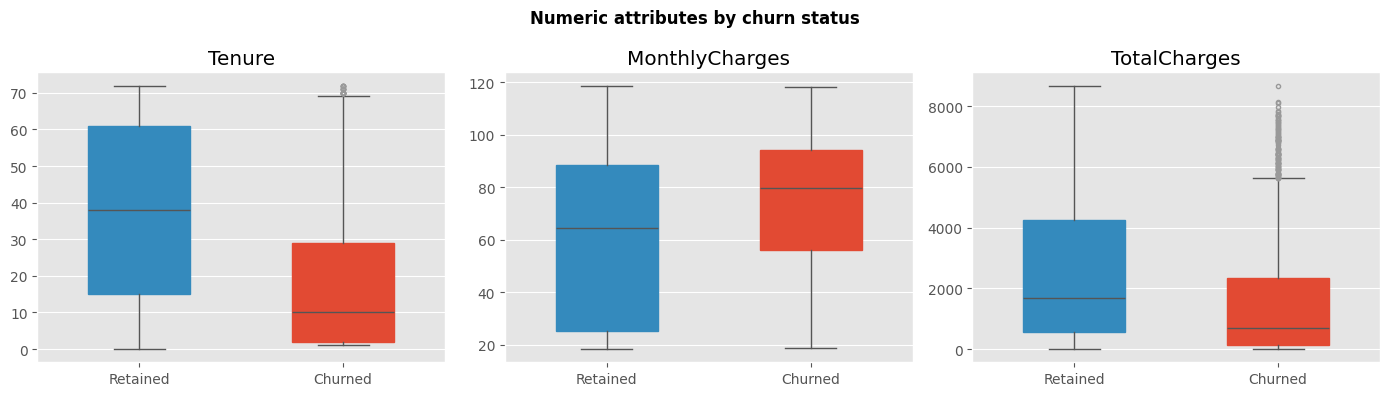

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Tenure", "MonthlyCharges", "TotalCharges"]):
    data = [df[df["Churn"] == "No"][col], df[df["Churn"] == "Yes"][col]]
    bp = ax.boxplot(data, tick_labels=["Retained", "Churned"], patch_artist=True, widths=0.5)
    for patch, colour in zip(bp["boxes"], [SAFE, RISK]):
        patch.set_facecolor(colour)
        patch.set_edgecolor(colour)
    for element in ["whiskers", "caps", "medians"]:
        plt.setp(bp[element], color="#555555")
    plt.setp(bp["fliers"], markeredgecolor="#999999", markersize=3)
    ax.set_title(col)
    ax.grid(axis="x", visible=False)

fig.suptitle("Numeric attributes by churn status", fontsize=12, fontweight="bold")
plt.tight_layout()

In [25]:
df.groupby("Churn")[["Tenure", "MonthlyCharges", "TotalCharges"]].mean().round(2)

,Tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2549.91
Yes,17.98,74.44,1531.80


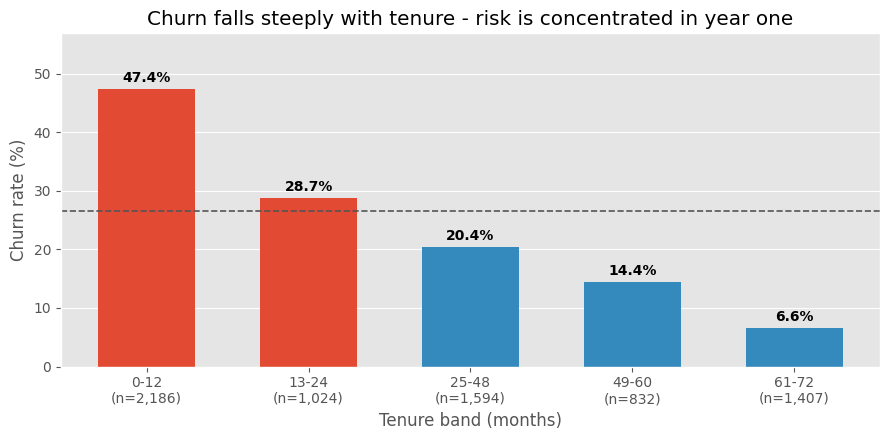

In [28]:
bands = pd.cut(df["Tenure"],
               bins=[-0.1, 12, 24, 48, 60, 72],
               labels=["0-12", "13-24", "25-48", "49-60", "61-72"])

rate = df.groupby(bands, observed=True)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
size = bands.value_counts().reindex(rate.index)

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = [RISK if v >= BASELINE else SAFE for v in rate.values]
names = [f"{b}\n(n={n:,})" for b, n in zip(rate.index.astype(str), size.values)]
bars = ax.bar(names, rate.values, width=0.6, color=colors)
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontweight="bold")

ax.axhline(BASELINE, color="#555555", linestyle="--", linewidth=1.2)
ax.set_xlabel("Tenure band (months)")
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn falls steeply with tenure - risk is concentrated in year one")
ax.set_ylim(0, rate.max() * 1.2)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
